# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random
import os

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)
from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

ML runs from high and low noise

In [2]:
runs_to_download = []
# Low and high noise
runs_to_download.extend(
    mlflow.search_runs(filter_string=f"attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction'",
                        experiment_ids=['7'], output_format='list'))
# Medium noise
runs_to_download.extend(mlflow.search_runs(
    filter_string="attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction' and tags.mlflow.parentRunId = 'f02bf732b2ba4817b254bd5174f1549b'",
      experiment_ids=['6'], output_format='list'))
print(len(runs_to_download))
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-05-06 15:41:32,859 - INFO - Downloading artifacts for run 9fce5b0c71f545eab13893c9b44ec0d7


33


2026-05-06 15:41:34,931 - INFO - Downloading artifacts for run 068867cc00fb48df8970e3c97b488b28
2026-05-06 15:41:35,848 - INFO - Downloading artifacts for run 7d69e80e283544f39a7eab67c7503515
2026-05-06 15:41:36,735 - INFO - Downloading artifacts for run e9470001774949b1976eef71572037cd
2026-05-06 15:41:37,632 - INFO - Downloading artifacts for run d870458d0b5243d9a6cb35f0b3ada3aa
2026-05-06 15:41:38,547 - INFO - Downloading artifacts for run 8932651904e746d8a6ea3489e2e1860d
2026-05-06 15:41:39,450 - INFO - Downloading artifacts for run 309801d3775d45bda1aebdafde6925ca
2026-05-06 15:41:40,391 - INFO - Downloading artifacts for run b93313eef4d34ee1b065350b2aaf6bef
2026-05-06 15:41:41,340 - INFO - Downloading artifacts for run d109d3154485488e95c947f7d4476523
2026-05-06 15:41:42,281 - INFO - Downloading artifacts for run b571f3dd78084648b7c842dc4a84fae4
2026-05-06 15:41:43,222 - INFO - Downloading artifacts for run 1836b03b24124c459b6ed5bba70dc3ae
2026-05-06 15:41:44,160 - INFO - Downloa

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_9,0.0,0.328551,0.328551,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a
1,Node_18,0.0,0.173930,0.173930,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a
2,Node_14,0.0,0.125051,0.125051,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a
3,Node_21,0.0,0.376956,0.376956,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a
4,Node_36,0.0,0.222967,0.222967,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a


In [3]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None)})
model_name_df = pd.DataFrame(model_name_records)
model_name_df

,run_id,model_name,modelled_genes
0,9fce5b0c71f545eab13893c9b44ec0d7,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
1,068867cc00fb48df8970e3c97b488b28,PyTorchODE,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '..."
2,7d69e80e283544f39a7eab67c7503515,PyTorchODE,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No..."
3,e9470001774949b1976eef71572037cd,PyTorchODE,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
4,d870458d0b5243d9a6cb35f0b3ada3aa,PyTorchODE,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod..."
5,8932651904e746d8a6ea3489e2e1860d,PyTorchODE,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No..."
6,309801d3775d45bda1aebdafde6925ca,PyTorchODE,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
7,b93313eef4d34ee1b065350b2aaf6bef,PyTorchODE,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod..."
8,d109d3154485488e95c947f7d4476523,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
9,b571f3dd78084648b7c842dc4a84fae4,PyTorchODE,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '..."


In [4]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')

Add number of genes and noise level

In [5]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    run = mlflow.get_run(run_id)
    records.append({
        'parent_run_id': run_id,
        'nr_genes': run.data.params['nr_genes'],
        'noise_level': run.data.params['noise_level'],
    })
nr_genes_df = pd.DataFrame(records)
nr_genes_df.head()

,parent_run_id,nr_genes,noise_level
0,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
1,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM
2,d97c3c9ca88a43b597b360151b25d316,50,HIGH


Add noiseless expression values

In [6]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-05-06 15:42:17,446 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-06 15:42:17,459 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-06 15:42:17,493 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-06 15:42:17,501 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-06 15:42:17,528 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-06 15:42:17,540 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-06 15:42:17,564 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-05-06 15:42:17,572 - WARNING - Connection p

In [7]:
nr_genes_df.head()

,parent_run_id,nr_genes,noise_level
0,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
1,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM
2,d97c3c9ca88a43b597b360151b25d316,50,HIGH


In [8]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes
0,Node_9,0.0,0.328551,0.328551,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
1,Node_18,0.0,0.173930,0.173930,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
2,Node_14,0.0,0.125051,0.125051,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
3,Node_21,0.0,0.376956,0.376956,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
4,Node_36,0.0,0.222967,0.222967,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."


In [9]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.022225,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
1,Node_1,0.0,0.557310,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
2,Node_2,0.0,0.080057,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
3,Node_3,0.0,0.702816,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
4,Node_4,0.0,0.057769,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a


Merging

In [32]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

outcome = pd.merge(outcome, nr_genes_df, on='parent_run_id')

In [33]:
outcome

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,modelled_genes,ground_truth_from_simulation,run_id_from_simulation,nr_genes,noise_level
0,Node_9,0.0,0.328551,0.328551,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.354691,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
1,Node_18,0.0,0.173930,0.173930,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.116035,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
2,Node_14,0.0,0.125051,0.125051,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.161193,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
3,Node_21,0.0,0.376956,0.376956,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.389304,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
4,Node_36,0.0,0.222967,0.222967,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,7e31a31d88f2426cbd3ec72a483bf90a,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.200109,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1963642,Node_45,1.0,1.003480,0.821199,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,0.925542,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM
1963643,Node_46,1.0,0.394155,0.294828,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,0.321352,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM
1963644,Node_47,1.0,0.190476,0.136453,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,0.138196,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM
1963645,Node_48,1.0,0.806056,0.756552,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,0.833160,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM


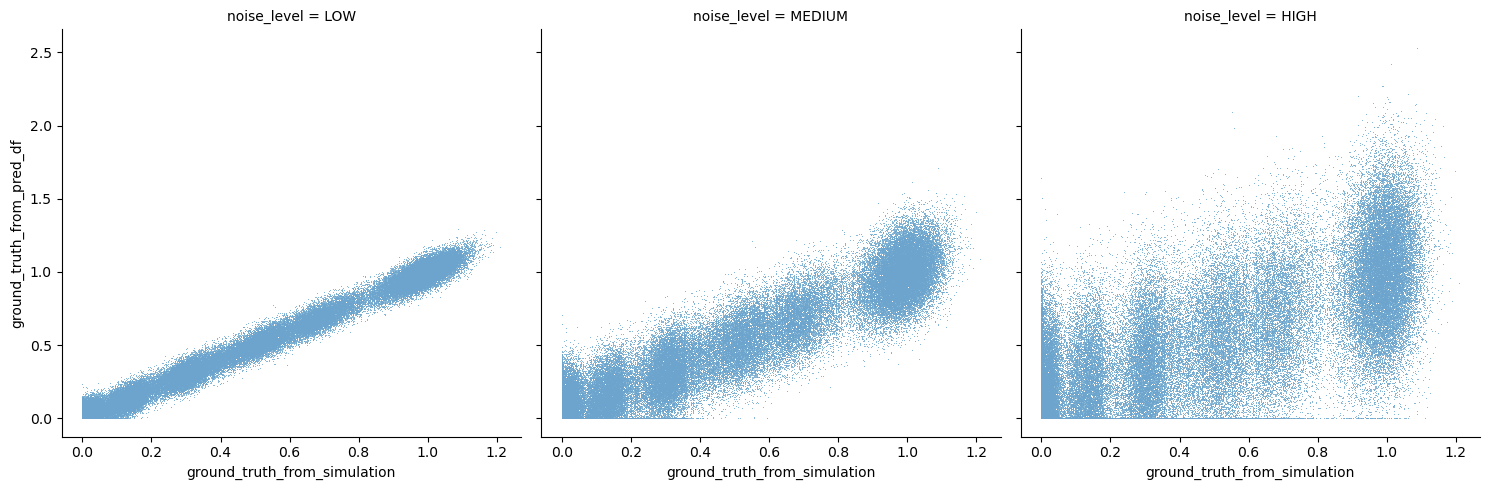

In [12]:
sns.relplot(data=outcome, x='ground_truth_from_simulation', y='ground_truth_from_pred_df', col='noise_level', s=2, alpha=.2, marker='.')

In [34]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'noise_level']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})


outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,noise_level
0,Node_9,0.0,0.328551,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.354691,LOW
1,Node_18,0.0,0.173930,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.116035,LOW
2,Node_14,0.0,0.125051,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.161193,LOW
3,Node_21,0.0,0.376956,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.389304,LOW
4,Node_36,0.0,0.222967,KO: Node_14. Env: None,9fce5b0c71f545eab13893c9b44ec0d7,PyTorchODE,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.200109,LOW
...,...,...,...,...,...,...,...,...,...
1963642,Node_45,1.0,1.003480,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.925542,MEDIUM
1963643,Node_46,1.0,0.394155,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.321352,MEDIUM
1963644,Node_47,1.0,0.190476,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.138196,MEDIUM
1963645,Node_48,1.0,0.806056,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.833160,MEDIUM


In [38]:
import string
genes_to_letter_map = {}
for i, genes in enumerate(outcome['modelled_genes'].unique()):
    if genes is None:
        continue
    genes_to_letter_map[genes] = string.ascii_uppercase[i]
genes_to_letter_map

{"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'Node_36', 'Node_40', 'Node_41']": 'A',
 "['Node_30', 'Node_39', 'Node_10', 'Node_22', 'Node_26', 'Node_32', 'Node_33', 'Node_49']": 'B',
 "['Node_13', 'Node_0', 'Node_24', 'Node_5', 'Node_4', 'Node_28', 'Node_29', 'Node_19']": 'C',
 "['Node_11', 'Node_1', 'Node_8', 'Node_31', 'Node_15', 'Node_16', 'Node_20', 'Node_38', 'Node_27', 'Node_34', 'Node_42', 'Node_44', 'Node_46']": 'D',
 "['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Node_12', 'Node_7', 'Node_25', 'Node_17', 'Node_35', 'Node_37', 'Node_43', 'Node_45', 'Node_47', 'Node_48']": 'E'}

In [44]:
outcome['model_name_long'] = outcome['model_name'] + ' ' + outcome['modelled_genes'].map(genes_to_letter_map).fillna('')
outcome['model_name_long'].nunique()

11

In [45]:
outcome['model_name_long'].unique().tolist()

['PyTorchODE A',
 'PyTorchODE B',
 'PyTorchODE C',
 'PyTorchODE D',
 'PyTorchODE E',
 'MLP ',
 'HybridModel E',
 'HybridModel D',
 'HybridModel A',
 'HybridModel C',
 'HybridModel B']

In [46]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [47]:
from sklearn.metrics import mean_squared_error
import re

groupby_list = [
    'model_name_long',
    'modelled_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'noise_level'
]
mse_df_long_model_name = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)


In [48]:
mse_df_long_model_name

,model_name_long,modelled_genes,gene,condition,noise_level,MSE
0,HybridModel A,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",Node_0,"KO: Node_0, Node_13. Env: None",HIGH,0.027862
1,HybridModel A,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",Node_0,"KO: Node_0, Node_13. Env: None",LOW,0.055281
2,HybridModel A,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",Node_0,"KO: Node_0, Node_13. Env: None",MEDIUM,0.035913
3,HybridModel A,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",Node_0,"KO: Node_0, Node_19. Env: None",HIGH,0.043639
4,HybridModel A,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",Node_0,"KO: Node_0, Node_19. Env: None",LOW,0.067423
...,...,...,...,...,...,...
46876,PyTorchODE E,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",Node_7,"KO: Node_7, Node_23. Env: None",LOW,0.000005
46877,PyTorchODE E,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",Node_7,"KO: Node_7, Node_23. Env: None",MEDIUM,0.000005
46878,PyTorchODE E,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",Node_7,"KO: Node_7, Node_35. Env: None",HIGH,0.005296
46879,PyTorchODE E,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",Node_7,"KO: Node_7, Node_35. Env: None",LOW,0.000124


In [61]:
# Only keep the MLP and hybrid model
mse_df_long_model_name_no_mm = mse_df_long_model_name[~mse_df_long_model_name['model_name_long'].str.contains('PyTorchODE')]
only_mm_df = mse_df_long_model_name[mse_df_long_model_name['model_name_long'].str.contains('PyTorchODE')]
only_mm_df.loc[:, 'model_name_long'] = only_mm_df['model_name_long'].str.replace('PyTorchODE', 'Mechanistic Model')
print(mse_df_long_model_name_no_mm['model_name_long'].unique().tolist())
print()
print(only_mm_df['model_name_long'].unique().tolist())

['HybridModel A', 'HybridModel B', 'HybridModel C', 'HybridModel D', 'HybridModel E', 'MLP ']

['Mechanistic Model A', 'Mechanistic Model B', 'Mechanistic Model C', 'Mechanistic Model D', 'Mechanistic Model E']


In [62]:
import matplotlib.colors as mcolors

hybrid_names = [n for n in mse_df_long_model_name_no_mm['model_name_long'].unique() if 'HybridModel' in n]
mlp_names = [n for n in mse_df_long_model_name_no_mm['model_name_long'].unique() if 'HybridModel' not in n]

hybrid_colours = sns.blend_palette(["#f5a623", "#d45f00"], n_colors=len(hybrid_names))
mlp_colours = sns.blend_palette(["#4a90d9", "#003f7f"], n_colors=len(mlp_names))

palette = {name: colour for name, colour in zip(hybrid_names, hybrid_colours)}
palette.update({name: colour for name, colour in zip(mlp_names, mlp_colours)})
palette = {name: mcolors.to_hex(colour) for name, colour in palette.items()}

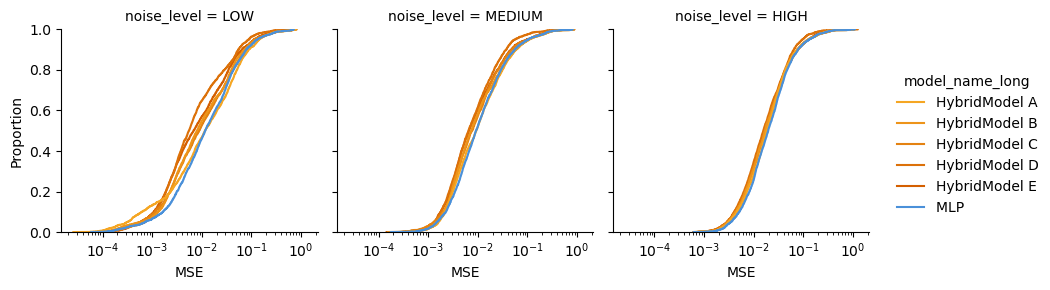

In [73]:
g = sns.displot(data=mse_df_long_model_name_no_mm, col='noise_level', col_order=['LOW', 'MEDIUM', 'HIGH'], x='MSE', hue='model_name_long', kind='ecdf', log_scale=True, palette=palette, height=3)

for ax in g.axes.flat:
    lines = ax.get_lines()
    for line in lines:
        if mcolors.to_hex(line.get_color()) in [palette[name] for name in mlp_names]:
            line.set_zorder(10)
g.savefig("noise_level_ecdf.pdf", dpi=600, bbox_inches='tight', )

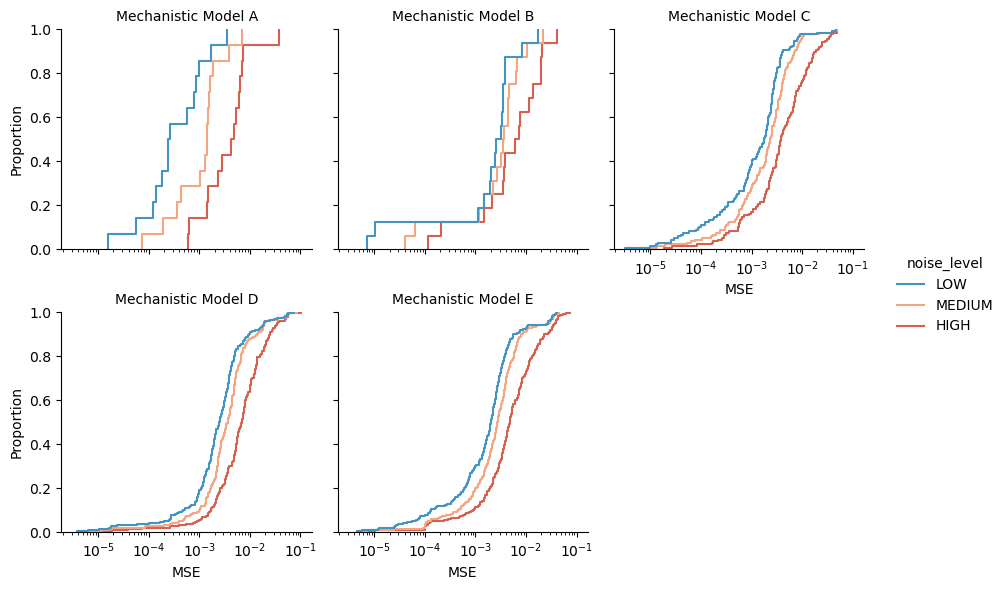

In [74]:
noise_palette = {"LOW": "#4393c3", "MEDIUM": "#f4a582", "HIGH": "#d6604d"}

g = sns.displot(only_mm_df, col='model_name_long', x='MSE', hue='noise_level', kind='ecdf',
                log_scale=True, hue_order=['LOW', 'MEDIUM', 'HIGH'],
                palette=noise_palette, height=3, aspect=1, col_wrap=3) 
g.set_titles("{col_name}")
g.savefig("mechanistic_model_noise_level_ecdf.pdf", dpi=600, bbox_inches='tight', )